# mmg_toolbox example
## Basic Functionality - Scans & Experiments
This short notebook describes how to load data from NeXus files.

### *Notebook Notes*
This notebook will run with any modern version of python and requires *mmg_toolbox*, which can be installed easily using:
```bash
python -m pip install mmg_toolbox
```

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import mmg_toolbox
from mmg_toolbox import Experiment, data_file_reader
from mmg_toolbox.plotting.matplotlib import set_plot_defaults

TEST_DIR = '/dls/science/groups/das/ExampleData/hdfmap_tests/'
print(mmg_toolbox.module_info())
set_plot_defaults()  # set nice defaults for matplotlib plots

Python version 3.14.5 (main, Jun  2 2026, 22:25:17) [Clang 22.1.3 ]
 at: /scratch/grp66007/python/mmg_toolbox/.venv/bin/python
 mmg_toolbox version 0.7.1 (17/09/2026): /scratch/grp66007/python/mmg_toolbox/mmg_toolbox/__init__.py
     numpy version: 2.5.3
      h5py version: 3.16.0
matplotlib version: 3.11.2
    hdfmap version: 1.4.0 (2026/08/28)
   tkinter version: 9.0



## Single File reading - the Scan Object
The scan object contains links to all the data in the NeXus file, allowing you to access it in a variety of different ways.

The scan object also includes a CONFIG table which is set specifically for the beamline it was collected from (this is normally determined automatically from the filename).

The scan object can be inspected to see what data is available using:

```python
print(scan)  # displays custom beamline specific metadata
print(scan.label())  # displays short title
print(scan.format('{cmd}'))  # returns formatted values from the NeXus file using the internal namespace
scan.plot()  # creates a default plot
data = scan.eval('signal / Transmission')  # returns evaluated expressions using the internal namespace
```

In [2]:
scan = data_file_reader(TEST_DIR + 'i06/i06-164261.nxs')
print(f"label: {scan.label()}")
print('\nBeamline Specific metadata:')
print(scan)


label: #164261

Beamline Specific metadata:

i06-164261.nxs
/dls/science/groups/das/ExampleData/hdfmap_tests/i06/i06-164261.nxs
2025-04-28 16:57:10.819000
user_input_command = zacscan 695 745 180 0.2
axes = /entry/zacmedipix/fastEnergy
signal = /entry/zacmedipix/data
detector = zacmedipix
shape = (900,)

endstation: PEEM
sample = name not given
energy = 695 eV
pol = lv
field x,y,z = (0.00, 0.00, 0.00) T
|field| = 0.00 T
temp = 300.00 K
theta = --
sample y pos = -- 
pitch = --



In [3]:
# Get data from scan
x, y = scan('axes, signal')  # returns arrays of default scanned data
print(f"Default axes shape (x-data): {x.shape}, signal shape (y-data): {y.shape}")
# metadata
field = scan('field_z?(0.0)')  # expressions can allow for multiple options and also defaults
print(f"Magnetic Field: {field:.3} T")
# Find names of metadata in the file
print('temperature fields:', scan.map.find_names('temperature'))
print(scan.format("Temperature: {temperature:.4} K"))



Default axes shape (x-data): (900,), signal shape (y-data): (900, 512, 512)
Magnetic Field: 0.0 T
temperature fields: ['temperature', 'EC1_temperature', 'NXcollection_temperature', 'OH1_temperature', 'Temperature', 'temperature_sensor_measurement', 'temperature_sensor_name', 'temperature_sensor_type', 'temperature_sensor', 'temperature_sensor_temperature_sensor', 'NXsensor_temperature_sensor']
Temperature: 22.71 K


In [4]:
# Look at the beamline specific config
print('\n'.join(f"{k:20}: {v}" for k, v in scan.config.items()))

config_file         : 
normalise_factor    : 
replace_names       : {'_t': '(count_time|counttime|t?(1.0))', 'count_time': '(count_time|counttime|t?(1.0))', 'cmd': '(cmd|user_input_command|user_command|scan_command)'}
roi                 : []
metadata_string     : 
{filename}
{filepath}
{start_time}
cmd = {(cmd|user_input_command|user_command|scan_command)}
axes = {_axes}
signal = {_signal}
detector = {_IMAGE.split('/')[-2] if '/' in _IMAGE else 'none'}
shape = {axes.shape}

endstation: {end_station}
sample = {sample_name}
energy = {mean((energyh|incident_energy)):.0f} eV
pol = {polarisation}
field x,y,z = ({field_x?(0):.2f}, {field_y?(0):.2f}, {field_z?(0):.2f}) T
|field| = {sqrt(field_x?(0)**2 + field_y?(0)**2 + field_z?(0)**2):.2f} T
temp = {(lakeshore336_cryostat|itc3_device_sensor_temp?(300)):.2f} K
theta = {s_scm_theta}
sample y pos = {s_scm_y} 
pitch = {s_m7_pitch}

metadata_list       : {'cmd': '{(cmd|user_input_command|user_command|scan_command)}'}
metadata_label      : {(cmd|

### Plotting



In [5]:
# The fields available as arrays for plotting are available here:
print('\n'.join(f"{k}: {v}" for k, v in  scan.map.scannables.items()))
# in addition, 'axes' and 'signal' will always point to the default scanned axes

fastEnergy: /entry/zacmedipix/fastEnergy
C1: /entry/instrument/fesData/C1
C2: /entry/instrument/fesData/C2
C3: /entry/instrument/fesData/C3
C4: /entry/instrument/fesData/C4
iddenergy: /entry/instrument/fesData/iddenergy
pgmenergy: /entry/instrument/fesData/pgmenergy
ROI1: /entry/instrument/fesData/ROI1
ROI2: /entry/instrument/fesData/ROI2
roi1io1: /entry/instrument/fesData/roi1io1
roi1io2: /entry/instrument/fesData/roi1io2
roi2io1: /entry/instrument/fesData/roi2io1
roi2io2: /entry/instrument/fesData/roi2io2
count_time: /entry/instrument/zacmedipix/count_time
Region1_meanvalue: /entry/instrument/zacmedipix/Region1_meanvalue


<Axes: title={'center': '#164261\nscan fastEnergy 0.0 899.0 1.0 fesData 0.0 1.0 zacmedipix 0.2'}, xlabel='fastEnergy', ylabel='Region1_meanvalue / C2'>

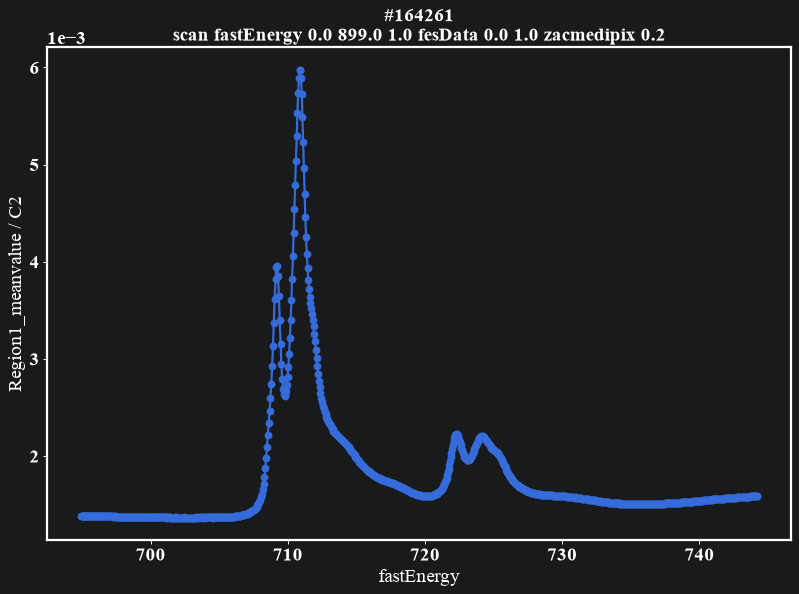

In [6]:
# create plot
scan.plot('axes', 'Region1_meanvalue / C2')

{'zacmedipix': '/entry/instrument/zacmedipix/data', 'IMAGE': '/entry/instrument/zacmedipix/data'}


<Axes: title={'center': '#164261\nfastEnergy [None] = 719.4849'}>

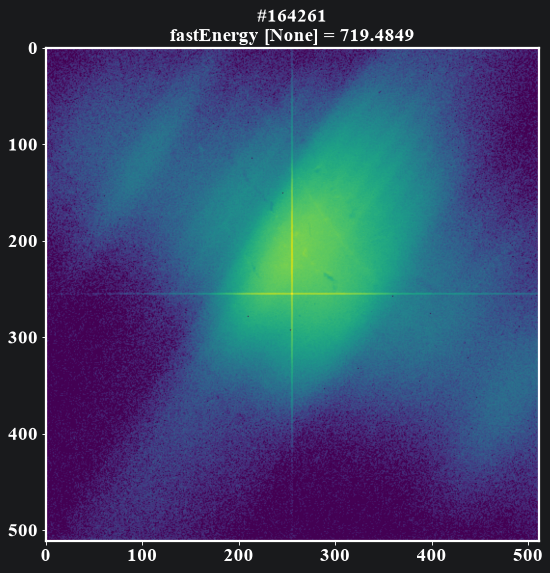

In [7]:
# Plot detector images
print(scan.map.image_data)  # detectors available
scan.plot.image(index=None, log=True)  # index can be an integer or None for the max value

Shape of scan: (51, 51)


<Axes: title={'center': '#1144224\nscan sy -1.1 0.9 0.04 sx 0 2 0.04 pil3_100k 0.5 roi1 roi2'}, xlabel='sy', ylabel='sx'>

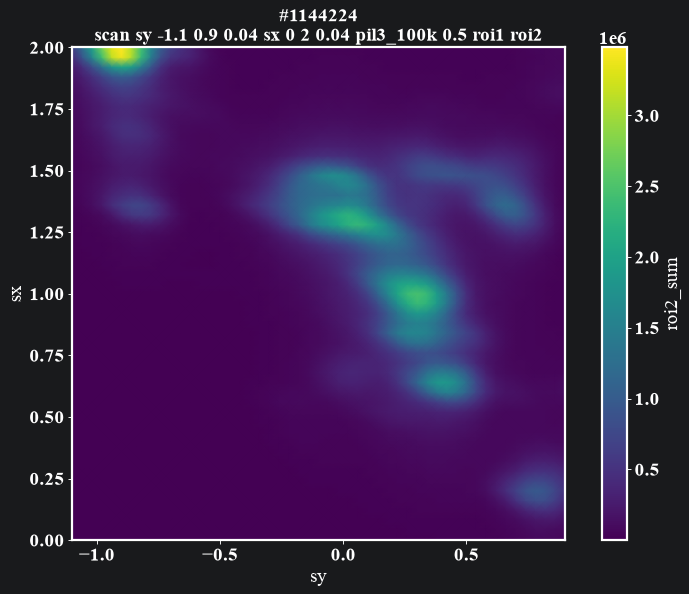

In [8]:
# 2D scan plots
scan2d = data_file_reader(TEST_DIR + 'i16/1144224.nxs')
print(f"Shape of scan: {scan2d.map.scannables_shape()}")
# Plot 2D raster scan
scan2d.plot.map2d()


## Multiple Files and Directories - the Experiment Object
The Experiment object monitors one or more data folders and associates scan numbers with filenames, allowing you to load directly from a scan number or range.

In [9]:
# Create experiment object - monitors one or more data folders for files
exp = Experiment('/dls/science/groups/das/ExampleData/i10-1/examples', instrument='i10-1')

print(exp)

# print all scans in directory (could take a while...)
print(exp.all_scans_str())

Instrument: i10-1
/dls/science/groups/das/ExampleData/i10-1/examples
    Files: 10
    Scans: 37442-37768
examples/i10-1-37442.nxs : 2025-06-23 13:43:34.980000     : cvscan energy 760 820 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37443.nxs : 2025-06-23 13:46:11.835000     : cvscan energy 760 820 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37444.nxs : 2025-06-23 13:50:19.273000     : cvscan energy 760 820 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37445.nxs : 2025-06-23 13:52:47.831000     : cvscan energy 760 820 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37620.nxs : 2025-06-24 01:10:17.096000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37621.nxs : 2025-06-24 01:12:46.727000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37622.nxs : 2025-06-24 01:15:34.710000     : cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
examples/i10-1-37623.nxs : 2025-06-24 01:20:17.440000 

In [10]:
# Load a data file as a Scan object
# input can be a filename or integer scan number or integer scan list index, where -1 is the latest scan
scan = exp.scan(-1)

print(scan)


i10-1-37768.nxs
/dls/science/groups/das/ExampleData/i10-1/examples/i10-1-37768.nxs
2025-06-25 16:45:51.032000
user_input_command = cvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 
axes = /entry/mcse17/energy
signal = /entry/mcse17/data
detector = none
shape = (601,)

endstation: --
sample = --
energy = 0 eV
pol = lv
field = 1.00 T
temp = 9.98 K
sample y pos = 46.00 
pitch = 0.00



### Accessing data
See https://diamondlightsource.github.io/hdfmap/usage/examples/ for more info.

In [11]:
# Access data in Scan object
axes, signal = scan('axes, axes')  # returns arrays (depending on underlying shape)
value = scan('mean(sample_temperature?(300))') # returns evaluated expression
string = scan.format('{sample_temperature?(300):.2f} K')  # returns formatted string
names = scan.find_names('field')  # return list of datasets in the file including sample_temperature?(300)

print(f"axes: {axes.shape}")
print(f"signal: {signal.shape}")
print(f"value: {value}")
print(f"string: {string}")
print(f"names: {names}")

axes: (601,)
signal: (601,)
value: 300.0
string: 300.00 K
names: ['NXcollection_field', 'field', 'magnetField', 'magnet_field', 'diamond_scan_scan_fields', 'NXcollection_scan_fields', 'scan_fields', 'entry_scan_fields', 'NXentry_scan_fields']


### Plotting data
Plotting is performed by default using matplotlib

<Axes: title={'center': '#37768\nscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2'}, xlabel='energy', ylabel='mcse17'>

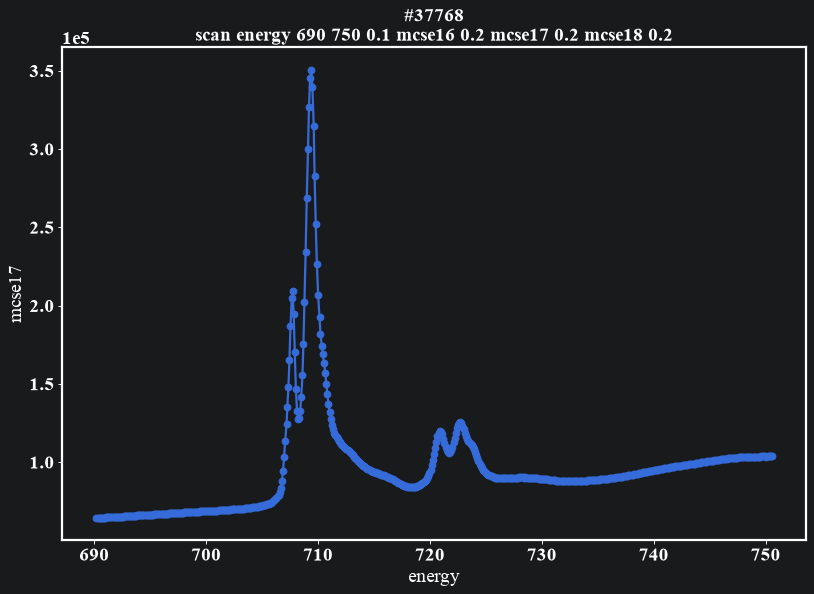

In [12]:
# default plot
scan.plot()

<Axes: title={'center': '#37768\nscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2'}, xlabel='energy', ylabel='mcse17'>

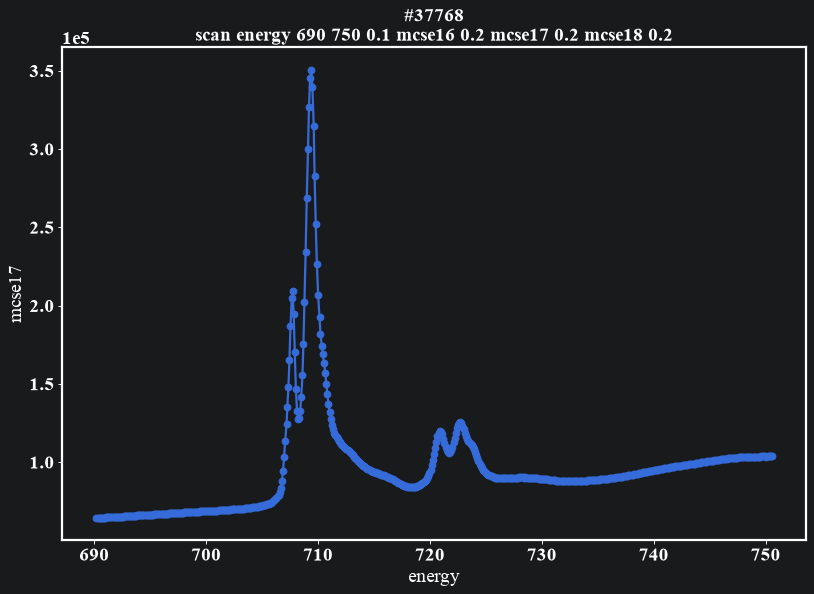

In [13]:
# Plot using different axes
# note that scan.plot is an abbreviation for scan.plot.plot, however other plot options are available in scan.plot
scan.plot.plot('axes', 'signal')


<Axes: title={'center': 'examples 3762[2,3] \ncvscan energy 690 750 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 '}, xlabel='energy', ylabel='mcse17'>

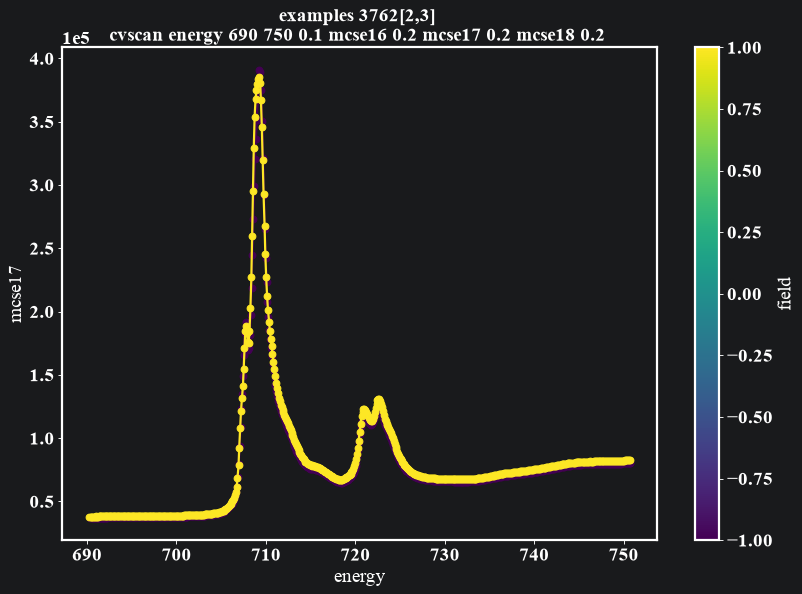

In [14]:
# Create multi-line plot from different experiments
exp.plot.multi_lines(*range(-4, -2), xaxis='axes', yaxis='signal', value='field')

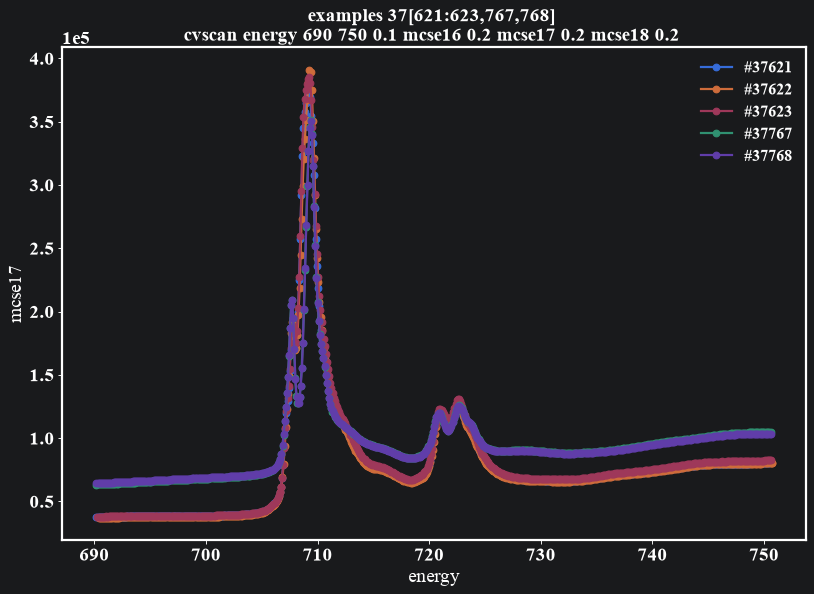

In [15]:
# Manual plotting (explicit matplotlib usage)
scans = exp.scans(*range(-5, 0))

fig, ax = plt.subplots()

for scan in scans:
    scan.plot.plotline('axes', 'signal', axes=ax)

scan.plot.axes_labels(title=exp.generate_scans_title(*scans))

plt.show()

### Fitting data
[lmfit](https://lmfit.github.io/lmfit-py/index.html) is used to perform fits, however specific wrappers are provided for peak fitting.

Fitting with 11 peaks


Text(0.5, 1.0, 'Fitting Example')

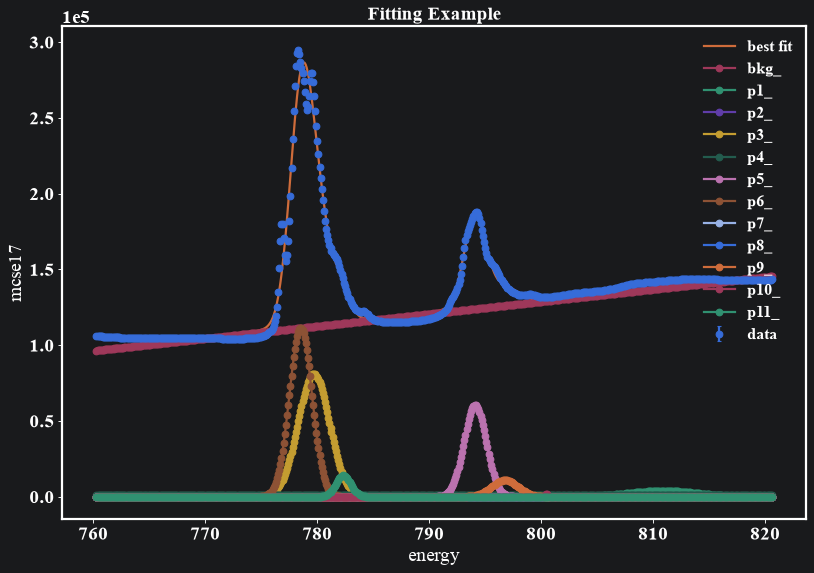

In [16]:
scan, = exp.scans(0)  # first scan

fig, ax = plt.subplots()

data = scan.get_plot_data('axes', 'signal')

# ax.plot(data['x'], data['y'], label=scan.title())

result = scan.fit.multi_peak_fit(
    xaxis='axes',  # default scan axes
    yaxis='signal',  # default scan values
    npeaks=None, # determine the number of peaks automatically
    min_peak_power=None,
    peak_distance_idx=6,
    model='Gaussian',
    background='Slope'
)
result.plot(axes=ax)

ax.set_xlabel(data['xlabel'])
ax.set_ylabel(data['ylabel'])
ax.set_title('Fitting Example')



### Plotting Metadata

<Axes: title={'center': 'examples 37[442:445,620:623,767,768] \ncvscan energy 760 820 0.1 mcse16 0.2 mcse17 0.2 mcse18 0.2 '}, xlabel='scan_number'>

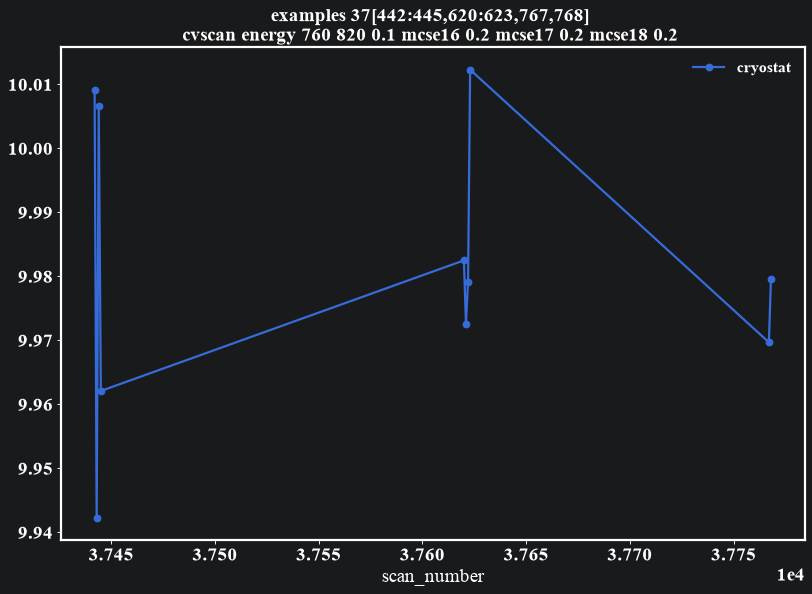

In [18]:
# Plot temperature values from all scans in experiment
exp.plot.metadata(values='cryostat', use_time=False, x_axis='scan_number')